# Malayalam Named Entity Recognition — 01. Data Exploration
This notebook loads the **Naamapadam (Malayalam)** corpus, looks at its statistics, and shows how word-level IOB2 tags are aligned to IndicBERTv2 subword tokens.

**Pipeline:** `01 Data Exploration` → `02 Model Training` → `03 Evaluation & Comparison` → `04 Inference & Demo`

## 0. Environment Setup
Works both **locally** (run from the project's `submission codes/` folder, which sits next to `dataset/` and `results/`) and on **Google Colab** (Runtime → Change runtime type → GPU).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "datasets<4" seqeval pytorch-crf

# Project root = folder that contains dataset/ and results/
PROJECT_DIR = os.path.abspath("..") if os.path.isdir(os.path.join("..", "dataset")) else os.path.abspath(".")
print("Running in Colab:", IN_COLAB)
print("Project directory:", PROJECT_DIR)

Running in Colab: False
Project directory: E:\Downloads\SEM 7\NLP\Project


In [2]:
import torch
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error(); disable_progress_bars()

# ---------------- Paths ----------------
DATA_DIR = os.path.join(PROJECT_DIR, "dataset")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_model")          # IndicBERTv2 + Linear head
CRF_MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_crf_model")  # IndicBERTv2 + CRF head

# ---------------- Hardware ----------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()

# ---------------- Model & labels (IOB2) ----------------
MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
ID2LABEL = {0: "O", 1: "B-PER", 2: "I-PER", 3: "B-ORG", 4: "I-ORG", 5: "B-LOC", 6: "I-LOC"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
NUM_LABELS = len(ID2LABEL)
ENTITY_COLORS = {"PER": "#3B82F6", "ORG": "#10B981", "LOC": "#F59E0B",
                 "MISC": "#8B5CF6", "DATE": "#EC4899", "CARDINAL": "#06B6D4"}

# ---------------- Hyperparameters (used for the final models) ----------------
MAX_LENGTH = 128
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 3
SEED = 42
MAX_TRAIN_SAMPLES = 50000

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

Device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU
torch 2.6.0+cu124


**Dataset.** If `dataset/*.csv` is not present (e.g. on Colab), the Malayalam split of [Naamapadam](https://huggingface.co/datasets/ai4bharat/naamapadam) is downloaded from HuggingFace and exported to the same CSV format.

In [3]:
def ensure_dataset():
    if all(os.path.exists(p) for p in (TRAIN_CSV, VAL_CSV, TEST_CSV)):
        print("Dataset found in", DATA_DIR)
        return
    from datasets import load_dataset
    ds = load_dataset("ai4bharat/naamapadam", "ml", trust_remote_code=True)
    os.makedirs(DATA_DIR, exist_ok=True)
    for split, path in [("train", TRAIN_CSV), ("validation", VAL_CSV), ("test", TEST_CSV)]:
        df = ds[split].to_pandas()[["tokens", "ner_tags"]]
        df["tokens"] = df["tokens"].map(lambda x: str(list(x)))
        df["ner_tags"] = df["ner_tags"].map(lambda x: str([int(t) for t in x]))
        df.to_csv(path, index=False)
    print("Dataset downloaded and saved to", DATA_DIR)

ensure_dataset()

Dataset found in E:\Downloads\SEM 7\NLP\Project\dataset


## 1. Data Loading
Each CSV row holds a tokenized sentence (`tokens`) and its integer IOB2 tags (`ner_tags`).

In [4]:
import ast
import pandas as pd
from torch.utils.data import Dataset


def load_ner_dataframe(csv_path, max_samples=None):
    """Loads CSV containing string representation of tokens and ner_tags."""
    df = pd.read_csv(csv_path)
    if max_samples and max_samples < len(df):
        df = df.iloc[:max_samples].copy()

    processed_records = []
    for idx, row in df.iterrows():
        try:
            tokens = ast.literal_eval(row['tokens']) if isinstance(row['tokens'], str) else row['tokens']
            tags = ast.literal_eval(row['ner_tags']) if isinstance(row['ner_tags'], str) else row['ner_tags']
            if len(tokens) == len(tags) and len(tokens) > 0:
                processed_records.append({"tokens": tokens, "ner_tags": tags})
        except Exception:
            continue

    return processed_records


class MalayalamNERDataset(Dataset):
    """PyTorch Dataset with HuggingFace Fast Tokenizer Subword Alignment."""

    def __init__(self, records, tokenizer, max_length=MAX_LENGTH):
        self.records = records
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]
        word_list = record['tokens']
        label_list = record['ner_tags']

        encoding = self.tokenizer(
            word_list,
            is_split_into_words=True,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        word_ids = encoding.word_ids(batch_index=0)
        aligned_labels = []
        previous_word_idx = None

        for word_idx in word_ids:
            if word_idx is None:
                # Special tokens ([CLS], [SEP], [PAD]) get -100 label
                aligned_labels.append(-100)
            elif word_idx != previous_word_idx:
                # First subword token of the word gets original label
                aligned_labels.append(label_list[word_idx])
            else:
                # Subsequent subword tokens get -100 so loss ignored
                aligned_labels.append(-100)
            previous_word_idx = word_idx

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(aligned_labels, dtype=torch.long)
        }

In [5]:
import pandas as pd
raw = pd.read_csv(TEST_CSV, nrows=3)
raw

,tokens,ner_tags
0,"['കോൺഗ്രസ്', 'സംസ്ഥാന', 'അധ്യക്ഷൻ', 'ജി', 'പരമ...","[3, 0, 0, 1, 2, 0, 0]"
1,"['ദക്ഷിണാഫ്രിക്ക', '-', 'ഡീൻ', 'എൽഗർ', ',', 'എ...","[5, 0, 1, 2, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0, 1, ..."
2,"['സഞ്ജുവിന്റെ', 'ഏറ്റവും', 'മികച്ച', 'പ്രകടനം'...","[1, 0, 0, 0, 0, 0]"


In [6]:
train_total = len(pd.read_csv(TRAIN_CSV, usecols=["ner_tags"]))
train_records = load_ner_dataframe(TRAIN_CSV, max_samples=MAX_TRAIN_SAMPLES)
val_records = load_ner_dataframe(VAL_CSV)
test_records = load_ner_dataframe(TEST_CSV)

print(f"Full training corpus      : {train_total:,} sentences")
print(f"Training subset used      : {len(train_records):,} sentences (MAX_TRAIN_SAMPLES = {MAX_TRAIN_SAMPLES:,})")
print(f"Validation set            : {len(val_records):,} sentences")
print(f"Test set                  : {len(test_records):,} sentences")

Full training corpus      : 716,652 sentences
Training subset used      : 50,000 sentences (MAX_TRAIN_SAMPLES = 50,000)
Validation set            : 3,618 sentences
Test set                  : 965 sentences


In [7]:
r = test_records[0]
pd.DataFrame({"token": r["tokens"], "tag_id": r["ner_tags"], "tag": [ID2LABEL[t] for t in r["ner_tags"]]})

,token,tag_id,tag
0,കോൺഗ്രസ്,3,B-ORG
1,സംസ്ഥാന,0,O
2,അധ്യക്ഷൻ,0,O
3,ജി,1,B-PER
4,പരമേശ്വര,2,I-PER
5,ഉപമുഖ്യമന്ത്രിയാകും,0,O
6,.,0,O


## 2. Corpus Statistics

In [8]:
from collections import Counter

def stats(records):
    tags = Counter(t for r in records for t in r["ner_tags"])
    ents = Counter(ID2LABEL[t][2:] for r in records for t in r["ner_tags"] if ID2LABEL[t].startswith("B-"))
    lens = [len(r["tokens"]) for r in records]
    return {"Sentences": len(records), "Tokens": sum(lens), "Avg. length": round(sum(lens) / len(lens), 2),
            "PER entities": ents["PER"], "ORG entities": ents["ORG"], "LOC entities": ents["LOC"],
            "% tokens tagged O": round(100 * tags[0] / sum(tags.values()), 2)}

split_stats = pd.DataFrame({"Train (subset)": stats(train_records), "Validation": stats(val_records), "Test": stats(test_records)})
split_stats

,Train (subset),Validation,Test
Sentences,50000.00,3618.00,965.00
Tokens,456631.00,33371.00,8534.00
Avg. length,9.13,9.22,8.84
PER entities,35057.00,2569.00,714.00
ORG entities,16265.00,1182.00,309.00
LOC entities,21333.00,1610.00,482.00
% tokens tagged O,74.06,73.99,70.92


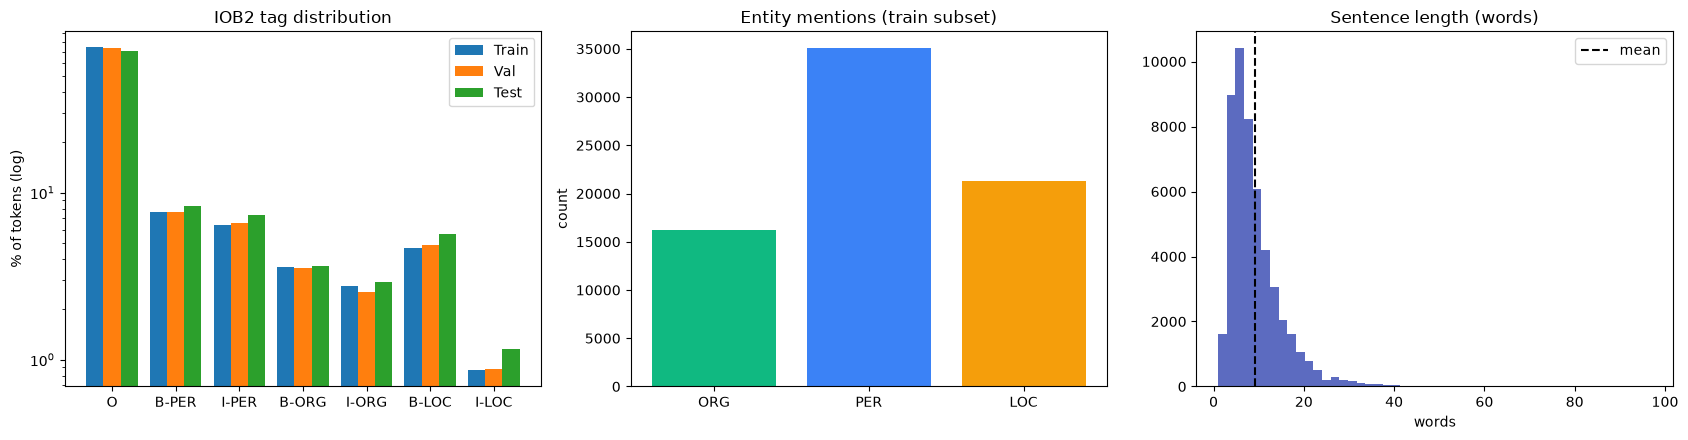

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
tags_order = [ID2LABEL[i] for i in range(NUM_LABELS)]

# (a) tag distribution (log scale, shows the heavy O imbalance)
for name, recs, off in [("Train", train_records, -0.27), ("Val", val_records, 0), ("Test", test_records, 0.27)]:
    c = Counter(t for r in recs for t in r["ner_tags"]); tot = sum(c.values())
    axes[0].bar(np.arange(NUM_LABELS) + off, [100 * c[i] / tot for i in range(NUM_LABELS)], width=0.27, label=name)
axes[0].set_xticks(range(NUM_LABELS)); axes[0].set_xticklabels(tags_order)
axes[0].set_yscale("log"); axes[0].set_ylabel("% of tokens (log)"); axes[0].set_title("IOB2 tag distribution"); axes[0].legend()

# (b) entity type distribution in the training subset
ents = Counter(ID2LABEL[t][2:] for r in train_records for t in r["ner_tags"] if ID2LABEL[t].startswith("B-"))
axes[1].bar(list(ents), list(ents.values()), color=[ENTITY_COLORS[k] for k in ents])
axes[1].set_title("Entity mentions (train subset)"); axes[1].set_ylabel("count")

# (c) sentence length
axes[2].hist([len(r["tokens"]) for r in train_records], bins=50, color="#3f51b5", alpha=.85)
axes[2].axvline(np.mean([len(r["tokens"]) for r in train_records]), color="k", ls="--", label="mean")
axes[2].set_title("Sentence length (words)"); axes[2].set_xlabel("words"); axes[2].legend()
plt.tight_layout(); plt.show()

In [10]:
# Entity span lengths (in words) — multi-word names are common for PER and ORG
span_len = {"PER": Counter(), "ORG": Counter(), "LOC": Counter()}
for r in train_records:
    cur, n = None, 0
    for t in [ID2LABEL[x] for x in r["ner_tags"]] + ["O"]:
        if t.startswith("I-") and cur == t[2:]:
            n += 1; continue
        if cur: span_len[cur][min(n, 5)] += 1
        cur, n = (t[2:], 1) if t.startswith("B-") else (None, 0)
pd.DataFrame(span_len).sort_index().rename(index={5: "5+"}).rename_axis("span length (words)")

,PER,ORG,LOC
span length (words),,,
1,13831,10130,18922
2,17079,3195,1568
3,2492,1507,513
4,646,690,201
5+,1009,743,129


## 3. Subword Tokenization & Label Alignment
Malayalam is highly agglutinative, so a single word is often split into several subwords. Only the **first subword** of every word keeps the word's tag; the remaining subwords and special tokens get `-100` and are ignored by the loss.

In [11]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

n_words = n_sub = 0
for r in test_records:
    for w in r["tokens"]:
        n_words += 1; n_sub += len(tokenizer.tokenize(w))
print(f"Tokenizer: {MODEL_NAME} (vocab size {tokenizer.vocab_size:,})")
print(f"Subword fertility on test set: {n_sub / n_words:.3f} subwords per word")

for w in ["തിരുവനന്തപുരത്ത്", "ഉപമുഖ്യമന്ത്രിയാകും", "ഐഎസ്ആർഒ"]:
    print(f"  {w:<22} -> {tokenizer.tokenize(w)}")

Tokenizer: ai4bharat/IndicBERTv2-MLM-only (vocab size 250,000)
Subword fertility on test set: 1.563 subwords per word
  തിരുവനന്തപുരത്ത്       -> ['തിരുവനന്തപുരത്ത്']
  ഉപമുഖ്യമന്ത്രിയാകും    -> ['ഉപമുഖ്യമന്ത്രി', '##യാകും']
  ഐഎസ്ആർഒ                -> ['ഐഎസ്', '##ആർ', '##ഒ']


In [12]:
dataset = MalayalamNERDataset(test_records[:10], tokenizer)
sample = dataset[0]
print({k: tuple(v.shape) for k, v in sample.items()})

toks = tokenizer.convert_ids_to_tokens(sample["input_ids"])
labs = sample["labels"].tolist()
n = int(sample["attention_mask"].sum())
pd.DataFrame({"subword": toks[:n], "label id": labs[:n],
              "label": [ID2LABEL[l] if l != -100 else "[MASKED -100]" for l in labs[:n]]})

{'input_ids': (128,), 'attention_mask': (128,), 'labels': (128,)}


,subword,label id,label
0,[CLS],-100,[MASKED -100]
1,കോൺഗ്രസ്,3,B-ORG
2,സംസ്ഥാന,0,O
3,അധ്യക്ഷൻ,0,O
4,ജി,1,B-PER
5,പരമേശ്വര,2,I-PER
6,ഉപമുഖ്യമന്ത്രി,0,O
7,##യാകും,-100,[MASKED -100]
8,.,0,O
9,[SEP],-100,[MASKED -100]


In [13]:
# Sanity check: number of supervised positions == number of words (unless truncated)
ok = sum(int((dataset[i]["labels"] != -100).sum()) == min(len(dataset.records[i]["tokens"]), MAX_LENGTH - 2) for i in range(len(dataset)))
print(f"{ok}/{len(dataset)} samples have one label per word — alignment verified.")

10/10 samples have one label per word — alignment verified.


## Summary
- The corpus is dominated by the `O` tag, which motivates **class-weighted loss** for the linear head and a **CRF** layer that models tag transitions.
- IndicBERTv2 splits each Malayalam word into ~1.5 subwords; first-subword label alignment keeps supervision at the word level.
- Next: `02_Model_Training.ipynb`.